In [1]:
import sys
print(sys.version)
print(sys.executable)

3.11.3 (tags/v3.11.3:f3909b8, Apr  4 2023, 23:49:59) [MSC v.1934 64 bit (AMD64)]
D:\work\repos\one-true-outcome-v1\.venv\Scripts\python.exe


In [2]:
import os
import base64
import requests
from google.oauth2 import service_account
from google.auth.transport.requests import Request
from IPython.display import Audio
song_file = "songs/theme_song.mp3"
if not os.path.exists(song_file):
    creds = service_account.Credentials.from_service_account_file("keys/service.json", scopes=["https://www.googleapis.com/auth/cloud-platform"])
    creds.refresh(Request())
    url = f"https://aiplatform.googleapis.com/v1beta1/projects/{creds.project_id}/locations/global/interactions"
    headers = {"Authorization": f"Bearer {creds.token}", "Content-Type": "application/json"}
    params = {"model": "lyria-3-clip-preview", "input": [{"type": "text", "text": "Echo and Mono winning theme song, upbeat cartoon baseball fanfare"}]}
    response = requests.post(url, headers=headers, json=params, timeout=90)
    response.raise_for_status()
    data = response.json()
    os.makedirs("songs", exist_ok=True)
    with open(song_file, "wb") as f:
        f.write(base64.b64decode(data["outputs"][2]["data"]))
    print("made", song_file)
print("theme song:", song_file)


service_account
song key loaded


In [3]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import Image, display
rng = np.random.default_rng(7)

theme song: songs/theme_song.mp3


In [5]:
hits_df = pd.read_csv("data/hits.csv")
hits_df.shape

(272, 4)

In [6]:
hits_df.head(3)

,player_name,events,launch_speed,launch_angle
0,"Caminero, Junior",field_out,102.1,40.0
1,"Aranda, Jonathan",field_out,97.5,-11.0
2,"Walls, Taylor",field_out,90.5,45.0


In [7]:
speed_min = 78
angle_min = -5 
angle_max = 55

def window(speed, angle):
    return (speed>= speed_min) & (angle >= angle_min) & (angle <= angle_max)

speed = hits_df["launch_speed"]
angle = hits_df["launch_angle"]
inside = window(speed,angle)
inside.head(3)

print(f'home-run window: {inside.sum()} of {len(hits_df)} can be home-runs')

home-run window: 142 of 272 can be home-runs


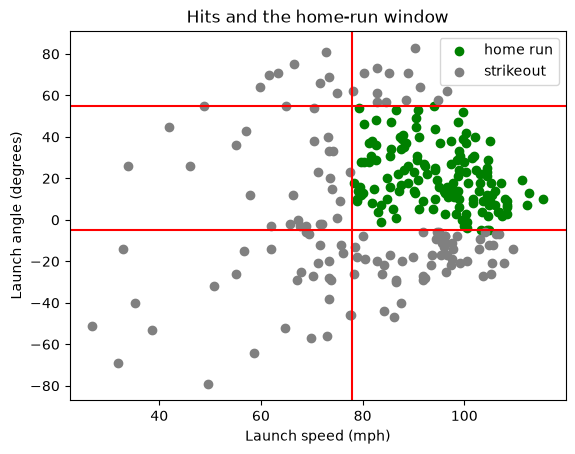

In [8]:
plt.scatter(speed[inside], angle[inside], color="green", label="home run")
plt.scatter(speed[~inside], angle[~inside], color="gray", label="strikeout")
plt.axvline(speed_min, color="red")
plt.axhline(angle_min, color="red")
plt.axhline(angle_max, color="red")
plt.title("Hits and the home-run window")
plt.xlabel("Launch speed (mph)")
plt.ylabel("Launch angle (degrees)")
plt.legend()
plt.show()

In [9]:
cards_df = pd.DataFrame(
    [
    ("bat", "1", "CURL NOISE GALE", "Curl noise makes swirling wind for VFX smoke and leaves, and it never piles up in one spot."),
    ("bat", "2", "LERP OVERSHOOT", "Lerp blends from slow to fast. Push t past 1 and it overshoots the target, the animator's trick for snap."),
    ("bat", "3", "FBM: +OCTAVES", "fBm stacks layers of noise (octaves). More octaves means wilder detail, and here wilder luck."),
    ("pitch", "1", "GROUND PLANE", "Snap an object to the floor in a 3D scene."),
    ("pitch", "2", "FRAME DROP", "Dropped frames make the motion stall."),
    ("pitch", "3", "DITHER", "CG noise breaks up smooth gradients.")
    ], columns=["role", "number", "name", "flavour"])

cards_df.head(3)

,role,number,name,flavour
0,bat,1,CURL NOISE GALE,Curl noise makes swirling wind for VFX smoke a...
1,bat,2,LERP OVERSHOOT,Lerp blends from slow to fast. Push t past 1 a...
2,bat,3,FBM: +OCTAVES,fBm stacks layers of noise (octaves). More oct...


In [10]:
# random engine + core game loop 
# so to ground us we have our ground truth csv of hits 
# the engine is roll_card -> roll_plan -> apply_chance
# 
# the jist of the game is each hit we randomly sample from we only care about 2 numbers
# bat speed and launch angle 
# we have a very simple measurement of what will constitute a home run
# each player has 3 power ups that can effect those 2 values 

# so the game starts, each player depending on if theyre pitching or hitting
# will first choose 2 of the 3 available cards and type in the selection
# 
# roll the selections of the cards and its effects
# add the solver steps all up 

# sample 1 random hit from our hits_df
# nudge it with the above summed solver results

# check to see if its a homerun or strikeout 

# for this MVP first version 
# batter has position effects towards the params 
# pitcher has negative effects towards the params

In [11]:
def card_name(role, number):
    return cards_df.loc[(cards_df["role"] == role) & (cards_df["number"] == number), "name"].iloc[0]
print("cards:", len(cards_df))

cards: 6


In [12]:
# we can also think of each card having a die to weights its effects
# returns 2 things, the number and a text 

def roll_card(low, high, lucky):
    first = rng.integers(low, high + 1)
    if not lucky:
        return first, ""
    second = rng.integers(low, high + 1)
    kept = max(first, second)
    return kept + 5, f": rolled {first} and {second}, kept {kept}, +5 = {kept + 5} ->"
print("card roller ready")


card roller ready


In [13]:
# a plan would be the decided 2 cards the players have chosen 
# this function will call roll-cards


def roll_plan(plan, role):
    sign = 1
    if role == "pitch":
        sign = -1
    lucky = "3" in plan
    luck = ""
    if lucky:
        luck = " + " + card_name(role, "3")
    mph = 0
    deg = 0
    lines = []
    if "1" in plan:
        push, how = roll_card(5, 15, lucky)
        deg = sign * push
        lines.append(card_name(role, "1") + luck + how + f" {deg:+} deg")
    if "2" in plan:
        push, how = roll_card(10, 20, lucky)
        mph = sign * push
        lines.append(card_name(role, "2") + luck + how + f" {mph:+} mph")
    return mph, deg, lines
print("plan roller ready")



plan roller ready


In [16]:
def at_bat(p_plan, b_plan):
    print("A (echo) pitches", p_plan + ", B (mono) bats", b_plan)
    p_mph, p_deg, p_lines = roll_plan(p_plan, "pitch")
    b_mph, b_deg, b_lines = roll_plan(b_plan, "bat")
    print("pitch:", ", ".join(p_lines))
    print("bat:", ", ".join(b_lines))
    mph = b_mph + p_mph
    deg = b_deg + p_deg
    print(f"nudge: {mph:+} mph, {deg:+} deg")
    row = hits_df.sample(1, random_state=rng).iloc[0]
    new_speed = round(row["launch_speed"] + mph, 1)
    new_angle = row["launch_angle"] + deg
    if window(new_speed, new_angle):
        result = "HOME RUN"
        winner = "B (the batter)"
        gif = "data/mono_home_run.gif"
        pose = "data/mono_win.png"
    else:
        result = "STRIKEOUT"
        winner = "A (the pitcher)"
        gif = "data/mono_strikeout.gif"
        pose = "data/echo_win.png"
    print("drawn:", row["player_name"], row["launch_speed"], "mph at", row["launch_angle"], "deg ->", new_speed, "mph at", new_angle, "deg ->", result)   # 1. added back
    print("winner:", winner)
    display(Image(filename=gif))
    display(Image(filename=pose, width=200))   # 2. the winner's picture
    return winner
print("at-bat ready")


at-bat ready


### Card reminder
- **Batter (B, Mono):** 1 CURL NOISE GALE: +5 to 15 deg · 2 LERP OVERSHOOT: +10 to 20 mph · 3 FBM: +OCTAVES: luck
- **Pitcher (A, Echo):** 1 GROUND PLANE: -5 to 15 deg · 2 FRAME DROP: -10 to 20 mph · 3 DITHER: luck
- **Luck card:** the other card rolls twice, mkeeps the bigger roll, and adds 5
- **Plans:** type 12, 13 or 23


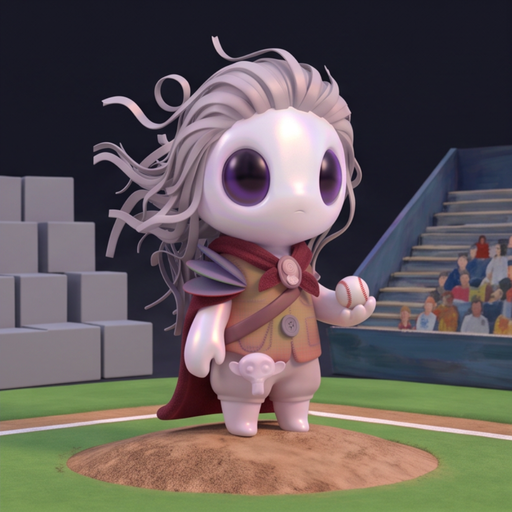

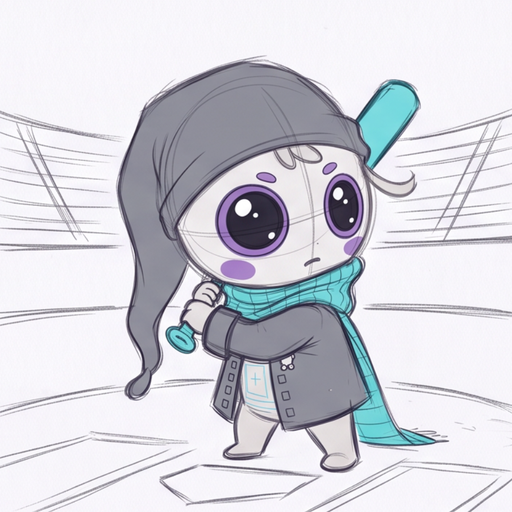

Password(description='Pitcher plan:')

Password(description='Batter plan:')

Button(description='Play', style=ButtonStyle())

Output()

Ready: A (echo) pitches, B (mono) bats.


In [19]:
pitch_box = widgets.Password(description="Pitcher plan:")
bat_box = widgets.Password(description="Batter plan:")
play_button = widgets.Button(description="Play")
output = widgets.Output()
def on_play(button):
    with output:
        p_plan = pitch_box.value
        b_plan = bat_box.value
        pitch_box.value = ""
        bat_box.value = ""
        at_bat(p_plan, b_plan)
        display(Audio(filename=song_file, autoplay=True))
play_button.on_click(on_play)
display(Image(filename="data/echo_ready_pitch.png", width=200), Image(filename="data/mono_ready_bat.png", width=200))
display(pitch_box, bat_box, play_button, output)
print("Ready: A (echo) pitches, B (mono) bats.")
